# 02 – Correlation Analysis (Spearman)

**Goal:** Examine how the 24 P_ predictors relate to heat-related illness (PR_HRI) and to each other.

Two versions are produced to match the two-part model:
1. **All ZCTAs** – supports Step 1 (floor vs. above floor)
2. **Above-floor ZCTAs only (PR_HRI > 20)** – supports Step 2 (regression on 40–99)

Spearman is used because several predictors are skewed (e.g., P_OZONE, P_PM25 are mostly zero) and PR_HRI has a floor at 20.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Path to the cleaned data from the EDA step.
# Change this to the file your teammate saved (CSV or Excel).
DATA_PATH = "HHI Data 2024 United States.csv"

FIG_DIR = "figures"   # folder where plots are saved
os.makedirs(FIG_DIR, exist_ok=True)   # create the folder if it doesn't exist

## 1. Load data and run safety checks

In [16]:
if DATA_PATH.endswith(".csv"):
    df = pd.read_csv(DATA_PATH)
else:
    df = pd.read_excel(DATA_PATH)

print("Rows, columns:", df.shape)

Rows, columns: (32195, 75)


In [17]:
# Predictors grouped by HHI module (P_ columns only)
modules = {
    "Heat":            ["P_NEHD"],
    "Sensitivity":     ["P_CHD", "P_OBS", "P_DIABETES", "P_COPD", "P_ASTHMA", "P_MNTHL"],
    "Sociodemographic":["P_UNINSUR", "P_POV", "P_UNEMP", "P_NOHSDP", "P_ISO",
                        "P_ELP", "P_DISABL", "P_ODW", "P_AGE65", "P_AGE5"],
    "Environment":     ["P_IMPERV", "P_TREEC", "P_NOVEH", "P_MOBILE",
                        "P_RENT", "P_OZONE", "P_PM25"],
}
predictors = [c for cols in modules.values() for c in cols]
target = "PR_HRI"
cols = [target] + predictors

# Check every expected column exists
missing_cols = [c for c in cols if c not in df.columns]
print("Missing columns:", missing_cols if missing_cols else "none")


# Check how many rows have at least one -999 (missing) value
print("Rows with -999:", (df[cols] == -999).any(axis=1).sum())

from sklearn.model_selection import train_test_split

# Same cleaning and split as the EDA notebook
df = df[cols]
df = df[np.logical_not((df == -999).any(axis=1))]
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

print("Clean rows:", len(df), "| Train:", len(train_df), "| Test:", len(test_df))

Missing columns: none
Rows with -999: 2074
Clean rows: 30121 | Train: 24096 | Test: 6025


## 2. Compute Spearman correlations

In [18]:
data_all   = train_df[cols]
data_above = train_df.loc[train_df[target] > 20, cols]

print(f"All ZCTAs:         {data_all[target].notna().sum():,} with PR_HRI")
print(f"Above-floor ZCTAs: {len(data_above):,}")

# Pairwise deletion: each pair uses all rows where both values exist
corr_all   = data_all.corr(method="spearman")
corr_above = data_above.corr(method="spearman")

All ZCTAs:         24,096 with PR_HRI
Above-floor ZCTAs: 14,640


## 3. Heatmaps (lower triangle, grouped by module)

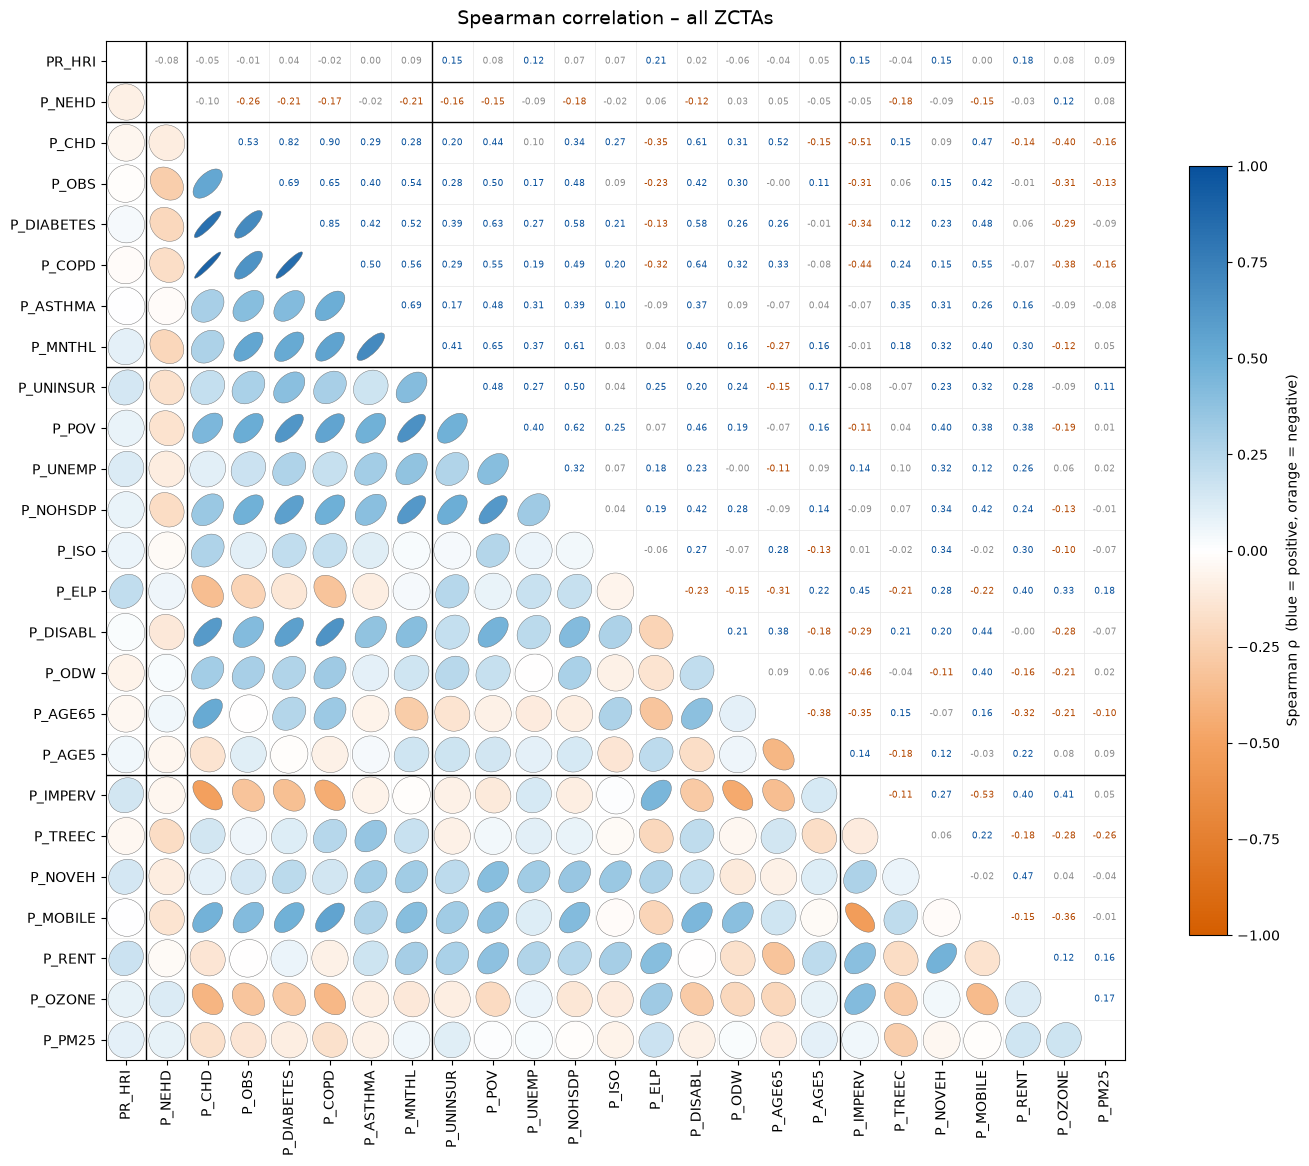

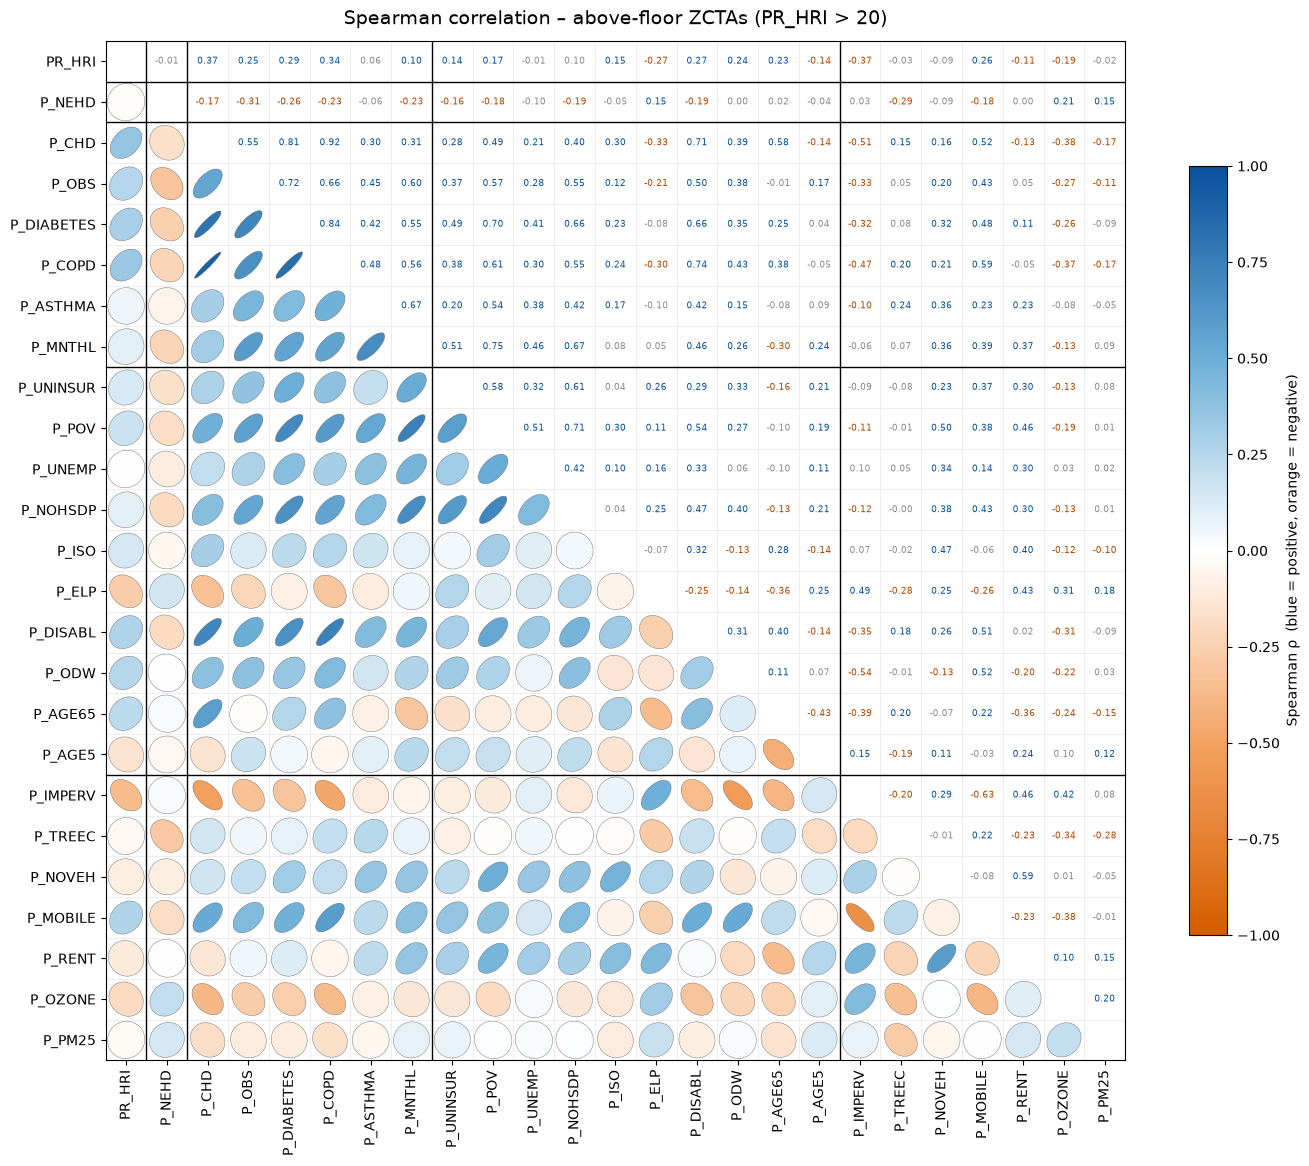

In [19]:
from matplotlib.collections import EllipseCollection
from matplotlib.colors import LinearSegmentedColormap

# Orange = negative, white = 0, blue = positive
cmap_ob = LinearSegmentedColormap.from_list(
    "orange_blue", ["#D55E00", "#F4A261", "#FFFFFF", "#6BAED6", "#08519C"]
)

def plot_corr(corr, title, filename):
    labels = corr.columns
    n = len(labels)
    M = corr.values

    fig, ax = plt.subplots(figsize=(14, 12))

    # Lower triangle: ellipses (narrower = stronger, tilt = direction)
    rows, cols = np.tril_indices(n, k=-1)
    vals = M[rows, cols]
    ec = EllipseCollection(
        widths=np.full(vals.shape, 0.9),
        heights=0.9 * (1 - np.abs(vals)) + 0.05,
        angles=45 * np.sign(vals),           # positive leans "/", negative leans "\"
        units="x",
        offsets=np.column_stack([cols, rows]),
        offset_transform=ax.transData,
        array=vals, cmap=cmap_ob, clim=(-1, 1),
        edgecolor="0.4", linewidth=0.3,
    )
    ax.add_collection(ec)

    # Upper triangle: correlation values (blue positive, orange negative, grey if |r| < 0.1)
    for i, j in zip(*np.triu_indices(n, k=1)):
        r = M[i, j]
        ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=6.5,
                color="#08519C" if r >= 0.1 else ("#B34700" if r <= -0.1 else "0.55"))

    # Axes and grid
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(labels, rotation=90)
    ax.set_yticklabels(labels)
    ax.set_xticks(np.arange(-0.5, n), minor=True)
    ax.set_yticks(np.arange(-0.5, n), minor=True)
    ax.grid(which="minor", color="0.9", linewidth=0.5)
    ax.tick_params(which="minor", length=0)
    ax.set_aspect("equal")

    # Lines separating the modules
    edges = np.cumsum([1] + [len(v) for v in modules.values()])[:-1]
    for e in edges:
        ax.axhline(e - 0.5, color="black", lw=1)
        ax.axvline(e - 0.5, color="black", lw=1)

    cbar = fig.colorbar(ec, ax=ax, shrink=0.7)
    cbar.set_label("Spearman ρ  (blue = positive, orange = negative)")
    ax.set_title(title, fontsize=14, pad=12)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{filename}", dpi=200, bbox_inches="tight")
    plt.show()

plot_corr(corr_all,   "Spearman correlation – all ZCTAs",                       "corr_all_zctas.png")
plot_corr(corr_above, "Spearman correlation – above-floor ZCTAs (PR_HRI > 20)", "corr_above_floor.png")

## 4. Correlation of each predictor with PR_HRI

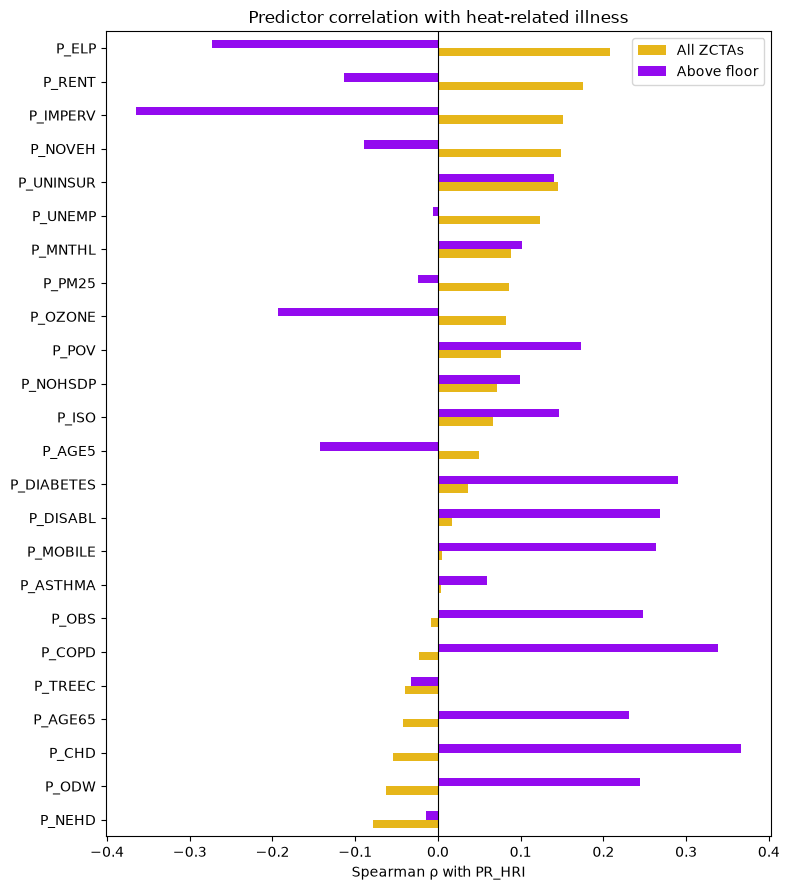

,All ZCTAs,Above floor
P_ELP,0.208,-0.273
P_RENT,0.175,-0.114
P_IMPERV,0.151,-0.365
P_NOVEH,0.148,-0.089
P_UNINSUR,0.146,0.140
P_UNEMP,0.123,-0.006
P_MNTHL,0.089,0.101
P_PM25,0.086,-0.024
P_OZONE,0.082,-0.193
P_NEHD,-0.079,-0.015


In [20]:
target_corr = pd.DataFrame({
    "All ZCTAs":   corr_all[target].drop(target),
    "Above floor": corr_above[target].drop(target),
}).sort_values("All ZCTAs")

ax = target_corr.plot.barh(figsize=(8, 9), color=["#E6B61A", "#930AEF"])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Spearman ρ with PR_HRI")
ax.set_title("Predictor correlation with heat-related illness")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/corr_with_pr_hri.png", dpi=200, bbox_inches="tight")
plt.show()

target_corr.round(3).sort_values("All ZCTAs", key=abs, ascending=False)

## 5. Highly correlated predictor pairs (|ρ| ≥ 0.7)
Flag these for the modeling step (multicollinearity).

In [21]:
pc = corr_all.loc[predictors, predictors]
upper = pc.where(np.triu(np.ones(pc.shape, dtype=bool), k=1))
pairs = (upper.stack()
              .rename("rho")
              .reset_index()
              .rename(columns={"level_0": "var_1", "level_1": "var_2"}))
high_pairs = pairs[pairs["rho"].abs() >= 0.7].sort_values("rho", key=abs, ascending=False)


# Same check for above-floor ZCTAs (used in Step 2 regression)
pc_above = corr_above.loc[predictors, predictors]
upper_above = pc_above.where(np.triu(np.ones(pc_above.shape, dtype=bool), k=1))
pairs_above = (upper_above.stack()
                          .rename("rho")
                          .reset_index()
                          .rename(columns={"level_0": "var_1", "level_1": "var_2"}))
high_above = pairs_above[pairs_above["rho"].abs() >= 0.7].sort_values("rho", key=abs, ascending=False)

print("All ZCTAs:")
display(high_pairs.round(3))
print("Above-floor ZCTAs:")
display(high_above.round(3))

All ZCTAs:


,var_1,var_2,rho
28,P_CHD,P_COPD,0.904
76,P_DIABETES,P_COPD,0.846
27,P_CHD,P_DIABETES,0.824


Above-floor ZCTAs:


,var_1,var_2,rho
28,P_CHD,P_COPD,0.919
76,P_DIABETES,P_COPD,0.840
27,P_CHD,P_DIABETES,0.811
152,P_MNTHL,P_POV,0.747
109,P_COPD,P_DISABL,0.741
51,P_OBS,P_DIABETES,0.716
202,P_POV,P_NOHSDP,0.708
37,P_CHD,P_DISABL,0.705
80,P_DIABETES,P_POV,0.703


## 6. Key findings

*(Write 3–5 bullets after reviewing the plots, for example:)*
- Strongest predictors of PR_HRI: …
- P_NEHD (extreme heat days) relationship with PR_HRI: …
- Differences between all ZCTAs and above-floor ZCTAs: …
- Highly correlated predictor groups to watch in modeling: …